In [ ]:
import pandas as pd
import os

print(os.listdir("/content"))


['.config', 'GeoXNet_Nanded_Test.csv', 'sample_data']


In [ ]:

import pandas as pd
import sklearn
import xgboost

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("All libraries are ready!")


Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1
All libraries are ready!


In [ ]:

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)
from xgboost import XGBClassifier

# 1. Load dataset
file_path = "/content/GeoXNet_Nanded_Balanced.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

# 2. Select input features and target
features = [
    "B2", "B3", "B4", "B5", "B6",
    "B7", "B8", "B8A", "B11", "B12",
    "NDVI", "NDWI", "NDBI"
]

X = df[features].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df["landcover"], errors="coerce")

# Remove invalid rows
valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

print("\nClass distribution:")
print(y.value_counts().sort_index())

# XGBoost expects class labels 0, 1, 2, 3
# Original labels: 1, 2, 3, 4
y_encoded = y - 1

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Train XGBoost baseline
model = XGBClassifier(
    objective="multi:softprob",
    num_class=4,
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

# Convert predictions back to original labels 1–4
y_test_original = y_test + 1
pred_original = pred + 1

# 5. Evaluate
print("\n========== GEOXNET: XGBOOST BASELINE ==========")
print(f"Accuracy:       {accuracy_score(y_test_original, pred_original):.4f}")
print(f"Macro Precision:{precision_score(y_test_original, pred_original, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:   {recall_score(y_test_original, pred_original, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score: {f1_score(y_test_original, pred_original, average='macro', zero_division=0):.4f}")
print(f"Cohen's Kappa:  {cohen_kappa_score(y_test_original, pred_original):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_original,
    pred_original,
    labels=[1, 2, 3, 4],
    target_names=["Water", "Greenery", "Barren", "Built-up"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_original, pred_original, labels=[1, 2, 3, 4]))

# 6. Save model and predictions
model.save_model("/content/xgboost_baseline.json")

results = X_test.copy()
results["actual_landcover"] = y_test_original
results["predicted_landcover"] = pred_original
results.to_csv("/content/xgboost_baseline_predictions.csv", index=False)

print("\nSaved model: xgboost_baseline.json")
print("Saved predictions: xgboost_baseline_predictions.csv")
print("\nBaseline experiment completed!")


Dataset shape: (4000, 14)

Class distribution:
landcover
1    1000
2    1000
3    1000
4    1000
Name: count, dtype: int64

Training samples: 3000
Testing samples: 1000

========== GEOXNET: XGBOOST BASELINE ==========
Accuracy:       0.9420
Macro Precision:0.9437
Macro Recall:   0.9420
Macro F1-score: 0.9423
Cohen's Kappa:  0.9227

Classification Report:
              precision    recall  f1-score   support

       Water       1.00      0.98      0.99       250
    Greenery       0.87      0.94      0.90       250
      Barren       0.99      0.98      0.99       250
    Built-up       0.92      0.87      0.89       250

    accuracy                           0.94      1000
   macro avg       0.94      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000

Confusion Matrix:
[[245   5   0   0]
 [  0 235   0  15]
 [  0   0 245   5]
 [  0  31   2 217]]

Saved model: xgboost_baseline.json
Saved predictions: xgboost_baseline_predictions.csv

Baseline experiment comp

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

folder = "/content/drive/MyDrive/GeoXNet"
print(os.listdir(folder))


Mounted at /content/drive
['GeoXNet_Nanded_Test.csv', 'GeoXNet_Nanded_Balanced.csv', 'GeoXNet_ResNet_SmallTest.tif']


In [ ]:

!pip -q install rasterio

import os
import rasterio
import numpy as np

tif_path = "/content/drive/MyDrive/GeoXNet/GeoXNet_ResNet_SmallTest.tif"

with rasterio.open(tif_path) as src:
    image = src.read()
    print("Raster shape (bands, height, width):", image.shape)
    print("Band count:", src.count)
    print("Data type:", src.dtypes)
    print("CRS:", src.crs)
    print("Pixel size:", src.res)
    print("No-data value:", src.nodata)

    rgb = np.moveaxis(image[:3], 0, -1)
    labels = image[3] if src.count >= 4 else None

print("\nRGB shape:", rgb.shape)
print("RGB value range:", np.nanmin(rgb), "to", np.nanmax(rgb))

if labels is not None:
    print("Label shape:", labels.shape)
    print("Unique label values:", np.unique(labels, return_counts=True))
else:
    print("No fourth label band found. We need to inspect the export.")


Raster shape (bands, height, width): (4, 1114, 1114)
Band count: 4
Data type: ('float32', 'float32', 'float32', 'float32')
CRS: EPSG:4326
Pixel size: (8.983152841195215e-05, 8.983152841195215e-05)
No-data value: None

RGB shape: (1114, 1114, 3)
RGB value range: 0.049 to 1.0
Label shape: (1114, 1114)
Unique label values: (array([ 0.,  1.,  3., nan], dtype=float32), array([ 49563,  68645, 156161, 966627]))


Patch dataset shape: (247, 32, 32, 3)
Labels shape: (247,)

Patch counts:
0 - Water: 48
1 - Greenery: 57
3 - Built-up: 142


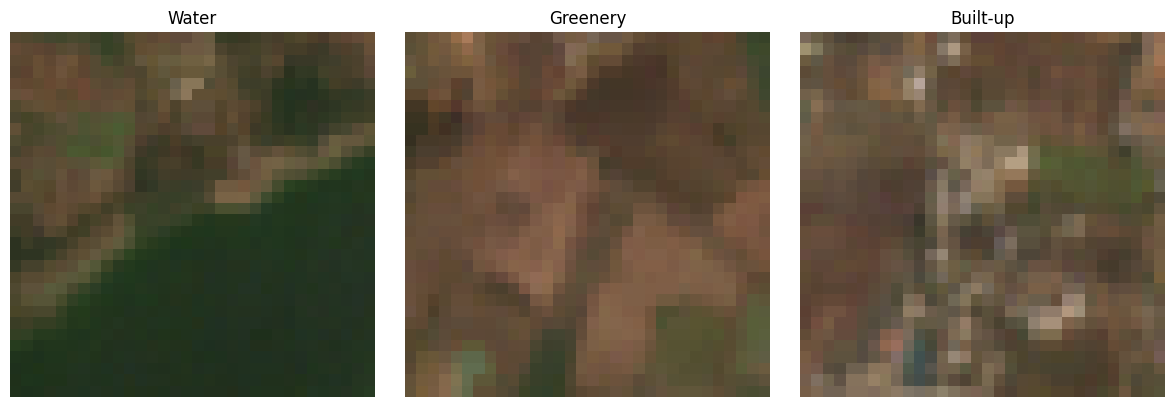

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

PATCH_SIZE = 32
HALF = PATCH_SIZE // 2

# Class mapping from the Earth Engine script:
# 0 = Water, 1 = Greenery, 2 = Barren, 3 = Built-up
class_names = {
    0: "Water",
    1: "Greenery",
    2: "Barren",
    3: "Built-up"
}

patches = []
patch_labels = []

height, width, _ = rgb.shape

# Slide across the raster and keep patches with valid center labels.
for row in range(HALF, height - HALF, PATCH_SIZE):
    for col in range(HALF, width - HALF, PATCH_SIZE):
        label = labels[row, col]

        if not np.isfinite(label):
            continue

        label = int(label)

        if label not in class_names:
            continue

        patch = rgb[
            row - HALF:row + HALF,
            col - HALF:col + HALF,
            :
        ]

        if patch.shape == (PATCH_SIZE, PATCH_SIZE, 3):
            if np.isfinite(patch).all():
                patches.append(patch.astype(np.float32))
                patch_labels.append(label)

patches = np.array(patches, dtype=np.float32)
patch_labels = np.array(patch_labels, dtype=np.int64)

print("Patch dataset shape:", patches.shape)
print("Labels shape:", patch_labels.shape)
print("\nPatch counts:")

for class_id, count in sorted(Counter(patch_labels).items()):
    print(f"{class_id} - {class_names[class_id]}: {count}")

# Preview one example patch per available class.
available_classes = sorted(np.unique(patch_labels))

fig, axes = plt.subplots(
    1, len(available_classes),
    figsize=(4 * len(available_classes), 4)
)
axes = np.atleast_1d(axes)

for ax, class_id in zip(axes, available_classes):
    idx = np.where(patch_labels == class_id)[0][0]
    ax.imshow(np.clip(patches[idx], 0, 1))
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# Keep only the three classes present in this raster.
# Original labels: 0=Water, 1=Greenery, 3=Built-up
class_ids = [0, 1, 3]
class_names = ["Water", "Greenery", "Built-up"]

mask = np.isin(patch_labels, class_ids)
X = patches[mask]
y_original = patch_labels[mask]

# Remap labels to 0, 1, 2 for PyTorch.
label_map = {0: 0, 1: 1, 3: 2}
y = np.array([label_map[int(v)] for v in y_original])

# Split the patch indices.
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# ImageNet normalization for pretrained ResNet.
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

class PatchDataset(Dataset):
    def __init__(self, X, y, indices):
        self.X = X
        self.y = y
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = self.indices[i]
        image = torch.from_numpy(self.X[idx]).permute(2, 0, 1)
        image = transforms.functional.resize(
            image, [224, 224], antialias=True
        )
        image = normalize(image)
        return image, int(self.y[idx])

train_ds = PatchDataset(X, y, train_idx)
test_ds = PatchDataset(X, y, test_idx)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Training patches:", len(train_ds))
print("Testing patches:", len(test_ds))

# Load pretrained ResNet-18.
try:
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
except Exception as e:
    print("Pretrained weights unavailable:", e)
    print("Using randomly initialized ResNet-18 for a pipeline test.")
    model = models.resnet18(weights=None)

# Freeze the pretrained feature extractor for this small test.
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 3)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

# Train for a few epochs.
for epoch in range(5):
    model.train()
    running_loss = 0.0

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {running_loss / len(train_ds):.4f}"
    )

# Evaluate on the held-out patch set.
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels_batch in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_true.extend(labels_batch.numpy())
        y_pred.extend(predictions)

print("\n========== RESNET-18 PIPELINE TEST ==========")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]))

torch.save(model.state_dict(), "/content/resnet18_smalltest.pth")
print("\nSaved: /content/resnet18_smalltest.pth")


Device: cpu
Training patches: 185
Testing patches: 62
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 74.1MB/s]


Epoch 1/5 | Loss: 1.1038
Epoch 2/5 | Loss: 0.7555
Epoch 3/5 | Loss: 0.5732
Epoch 4/5 | Loss: 0.5218
Epoch 5/5 | Loss: 0.4049

========== RESNET-18 PIPELINE TEST ==========
Accuracy: 0.8226
Macro F1: 0.771

Classification report:
              precision    recall  f1-score   support

       Water       0.90      0.75      0.82        12
    Greenery       0.78      0.50      0.61        14
    Built-up       0.81      0.97      0.89        36

    accuracy                           0.82        62
   macro avg       0.83      0.74      0.77        62
weighted avg       0.82      0.82      0.81        62

Confusion matrix:
[[ 9  1  2]
 [ 1  7  6]
 [ 0  1 35]]

Saved: /content/resnet18_smalltest.pth


In [ ]:

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# Three classes available in the current small image export
class_ids = [0, 1, 3]
class_names = ["Water", "Greenery", "Built-up"]

mask = np.isin(patch_labels, class_ids)
X = patches[mask].astype(np.float32)
y_original = patch_labels[mask]

# Remap original labels 0, 1, 3 to model labels 0, 1, 2
label_map = {0: 0, 1: 1, 3: 2}
y = np.array([label_map[int(v)] for v in y_original])

# Use exactly the same split as the ResNet experiment
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.25,
    random_state=42,
    stratify=y
)

normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

class PatchDataset(Dataset):
    def __init__(self, X, y, indices):
        self.X = X
        self.y = y
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = self.indices[i]
        image = torch.from_numpy(self.X[idx]).permute(2, 0, 1)
        image = transforms.functional.resize(
            image, [224, 224], antialias=True
        )
        image = normalize(image)
        return image, int(self.y[idx])

train_ds = PatchDataset(X, y, train_idx)
test_ds = PatchDataset(X, y, test_idx)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Training patches:", len(train_ds))
print("Testing patches:", len(test_ds))

# Load pretrained EfficientNet-B0
try:
    weights = models.EfficientNet_B0_Weights.DEFAULT
    model = models.efficientnet_b0(weights=weights)
except Exception as e:
    print("Pretrained weights unavailable:", e)
    print("Using random initialization for a pipeline test.")
    model = models.efficientnet_b0(weights=None)

# Freeze pretrained features and train the classification head
for param in model.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 3)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)

# Train for five epochs
for epoch in range(5):
    model.train()
    running_loss = 0.0

    for images, batch_labels in train_loader:
        images = images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {running_loss / len(train_ds):.4f}"
    )

# Evaluate
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, batch_labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu().numpy()
        y_true.extend(batch_labels.numpy())
        y_pred.extend(predictions)

print("\n========== EFFICIENTNET-B0 PIPELINE TEST ==========")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro precision:", round(
    precision_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Macro recall:", round(
    recall_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]))

torch.save(model.state_dict(), "/content/efficientnet_b0_smalltest.pth")
print("\nSaved: /content/efficientnet_b0_smalltest.pth")


Device: cpu
Training patches: 185
Testing patches: 62
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 33.5MB/s]


Epoch 1/5 | Loss: 0.8495
Epoch 2/5 | Loss: 0.5720
Epoch 3/5 | Loss: 0.4484
Epoch 4/5 | Loss: 0.4145
Epoch 5/5 | Loss: 0.3355

========== EFFICIENTNET-B0 PIPELINE TEST ==========
Accuracy: 0.8548
Macro precision: 0.8677
Macro recall: 0.791
Macro F1: 0.7954

Classification report:
              precision    recall  f1-score   support

       Water       1.00      0.50      0.67        12
    Greenery       0.68      0.93      0.79        14
    Built-up       0.92      0.94      0.93        36

    accuracy                           0.85        62
   macro avg       0.87      0.79      0.80        62
weighted avg       0.88      0.85      0.85        62

Confusion matrix:
[[ 6  4  2]
 [ 0 13  1]
 [ 0  2 34]]

Saved: /content/efficientnet_b0_smalltest.pth


In [ ]:

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

# Same class mapping used for both image models
class_names = ["Water", "Greenery", "Built-up"]

# Recreate the exact same test split
mask = np.isin(patch_labels, [0, 1, 3])
X = patches[mask].astype(np.float32)
y_original = patch_labels[mask]

label_map = {0: 0, 1: 1, 3: 2}
y = np.array([label_map[int(v)] for v in y_original])

from sklearn.model_selection import train_test_split

indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices, test_size=0.25, random_state=42, stratify=y
)

# Reuse the test dataset and loader from your previous cells.
# test_loader should contain the same test patches in order.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def get_probabilities(model, loader):
    model = model.to(device)
    model.eval()
    probabilities = []
    actual_labels = []

    with torch.no_grad():
        for images, batch_labels in loader:
            logits = model(images.to(device))
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probabilities.append(probs)
            actual_labels.extend(batch_labels.numpy())

    return np.vstack(probabilities), np.array(actual_labels)

# ResNet-18 model from your earlier training cell
resnet_probs, resnet_y = get_probabilities(model, test_loader)

print("ResNet probabilities:", resnet_probs.shape)
print("ResNet labels:", resnet_y.shape)


ResNet probabilities: (62, 3)
ResNet labels: (62,)


In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load each architecture independently.
resnet = models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 3)
resnet.load_state_dict(
    torch.load("/content/resnet18_smalltest.pth", map_location=device, weights_only=True)
)
resnet = resnet.to(device)

efficientnet = models.efficientnet_b0(weights=None)
efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features, 3
)
efficientnet.load_state_dict(
    torch.load("/content/efficientnet_b0_smalltest.pth",
               map_location=device, weights_only=True)
)
efficientnet = efficientnet.to(device)

def predict_probabilities(network, loader):
    network.eval()
    all_probs, all_labels = [], []

    with torch.no_grad():
        for images, batch_labels in loader:
            logits = network(images.to(device))
            all_probs.append(torch.softmax(logits, dim=1).cpu().numpy())
            all_labels.extend(batch_labels.numpy())

    return np.vstack(all_probs), np.array(all_labels)

resnet_probs, resnet_y = predict_probabilities(resnet, test_loader)
effnet_probs, effnet_y = predict_probabilities(efficientnet, test_loader)

assert np.array_equal(resnet_y, effnet_y), "Test labels do not match!"
assert resnet_probs.shape == effnet_probs.shape == (62, 3)

# Save actual labels and both probability matrices together.
prob_df = pd.DataFrame({
    "actual_class": resnet_y,
    "resnet_water": resnet_probs[:, 0],
    "resnet_greenery": resnet_probs[:, 1],
    "resnet_builtup": resnet_probs[:, 2],
    "effnet_water": effnet_probs[:, 0],
    "effnet_greenery": effnet_probs[:, 1],
    "effnet_builtup": effnet_probs[:, 2],
})

prob_df.to_csv("/content/geoxnet_dl_probabilities.csv", index=False)

print("ResNet probability shape:", resnet_probs.shape)
print("EfficientNet probability shape:", effnet_probs.shape)
print("Same test labels:", np.array_equal(resnet_y, effnet_y))
print("Saved: /content/geoxnet_dl_probabilities.csv")


ResNet probability shape: (62, 3)
EfficientNet probability shape: (62, 3)
Same test labels: True
Saved: /content/geoxnet_dl_probabilities.csv


In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

df = pd.read_csv("/content/geoxnet_dl_probabilities.csv")

y_true = df["actual_class"].to_numpy()

resnet_probs = df[
    ["resnet_water", "resnet_greenery", "resnet_builtup"]
].to_numpy()

effnet_probs = df[
    ["effnet_water", "effnet_greenery", "effnet_builtup"]
].to_numpy()

# Equal-weight probability fusion
fusion_probs = 0.5 * resnet_probs + 0.5 * effnet_probs

predictions = {
    "ResNet-18": resnet_probs.argmax(axis=1),
    "EfficientNet-B0": effnet_probs.argmax(axis=1),
    "ResNet + EfficientNet fusion": fusion_probs.argmax(axis=1)
}

print("========== COMPARISON ON THE SAME 62 PATCHES ==========")

for name, pred in predictions.items():
    accuracy = accuracy_score(y_true, pred)
    macro_f1 = f1_score(
        y_true, pred, labels=[0, 1, 2],
        average="macro", zero_division=0
    )

    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(classification_report(
        y_true, pred,
        labels=[0, 1, 2],
        target_names=["Water", "Greenery", "Built-up"],
        zero_division=0
    ))

# Save the comparison predictions
out = pd.DataFrame({
    "actual_class": y_true,
    "resnet_prediction": predictions["ResNet-18"],
    "efficientnet_prediction": predictions["EfficientNet-B0"],
    "fusion_prediction": predictions["ResNet + EfficientNet fusion"]
})

out.to_csv("/content/geoxnet_dl_fusion_predictions.csv", index=False)
print("\nSaved: geoxnet_dl_fusion_predictions.csv")


========== COMPARISON ON THE SAME 62 PATCHES ==========

ResNet-18
Accuracy: 0.8226
Macro F1: 0.7710
              precision    recall  f1-score   support

       Water       0.90      0.75      0.82        12
    Greenery       0.78      0.50      0.61        14
    Built-up       0.81      0.97      0.89        36

    accuracy                           0.82        62
   macro avg       0.83      0.74      0.77        62
weighted avg       0.82      0.82      0.81        62


EfficientNet-B0
Accuracy: 0.8548
Macro F1: 0.7954
              precision    recall  f1-score   support

       Water       1.00      0.50      0.67        12
    Greenery       0.68      0.93      0.79        14
    Built-up       0.92      0.94      0.93        36

    accuracy                           0.85        62
   macro avg       0.87      0.79      0.80        62
weighted avg       0.88      0.85      0.85        62


ResNet + EfficientNet fusion
Accuracy: 0.8871
Macro F1: 0.8405
              precisio

In [ ]:

import os
import random
import numpy as np
import pandas as pd
import rasterio
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

TIFF_PATH = "/content/GeoXNet_ResNet_SmallTest.tif"

if not os.path.exists(TIFF_PATH):
    raise FileNotFoundError(
        f"TIFF not found at {TIFF_PATH}. "
        "Check the Colab Files panel and upload the TIFF if necessary."
    )

with rasterio.open(TIFF_PATH) as src:
    rgb = src.read([1, 2, 3]).astype(np.float32)
    label_raster = src.read(4).astype(np.float32)

rgb = np.moveaxis(rgb, 0, -1)

print("RGB shape:", rgb.shape)
print("Label shape:", label_raster.shape)
print("Label values:", np.unique(label_raster[~np.isnan(label_raster)]))


RGB shape: (1114, 1114, 3)
Label shape: (1114, 1114)
Label values: [0. 1. 3.]


In [ ]:

PATCH_SIZE = 32
STRIDE = 32

# Original labels: 0=Water, 1=Greenery, 2=Barren, 3=Built-up
CLASS_NAMES = ["Water", "Greenery", "Built-up"]
LABEL_MAP = {0: 0, 1: 1, 3: 2}

patches_list = []
labels_list = []

height, width, _ = rgb.shape
half = PATCH_SIZE // 2

for cy in range(half, height - half + 1, STRIDE):
    for cx in range(half, width - half + 1, STRIDE):
        original_label = label_raster[cy, cx]

        if not np.isfinite(original_label):
            continue

        original_label = int(original_label)

        if original_label not in LABEL_MAP:
            continue

        patch = rgb[
            cy-half:cy+half,
            cx-half:cx+half,
            :
        ]

        if patch.shape != (PATCH_SIZE, PATCH_SIZE, 3):
            continue

        if not np.isfinite(patch).all():
            continue

        patches_list.append(patch)
        labels_list.append(LABEL_MAP[original_label])

patches = np.asarray(patches_list, dtype=np.float32)
patch_labels = np.asarray(labels_list, dtype=np.int64)

if len(patches) == 0:
    raise ValueError("No patches extracted. Check TIFF labels and image data.")

print("Patches:", patches.shape)
print("Labels:", patch_labels.shape)
print("Class counts:", {
    CLASS_NAMES[int(c)]: int(n)
    for c, n in zip(*np.unique(patch_labels, return_counts=True))
})


Patches: (247, 32, 32, 3)
Labels: (247,)
Class counts: {'Water': 48, 'Greenery': 57, 'Built-up': 142}


In [ ]:

indices = np.arange(len(patches))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.25,
    random_state=SEED,
    stratify=patch_labels
)

X_train_img = patches[train_idx]
X_test_img = patches[test_idx]
y_train = patch_labels[train_idx]
y_test = patch_labels[test_idx]

print("Train patches:", len(train_idx))
print("Test patches:", len(test_idx))
print("Test class counts:", np.bincount(y_test, minlength=3))


Train patches: 185
Test patches: 62
Test class counts: [12 14 36]


In [ ]:

def extract_patch_features(batch):
    feature_rows = []

    for patch in batch:
        features = []

        for channel in range(3):
            values = patch[:, :, channel].ravel()

            features.extend([
                values.mean(),
                values.std(),
                values.min(),
                values.max(),
                np.percentile(values, 25),
                np.percentile(values, 50),
                np.percentile(values, 75),
            ])

        feature_rows.append(features)

    return np.asarray(feature_rows, dtype=np.float32)

X_train_xgb = extract_patch_features(X_train_img)
X_test_xgb = extract_patch_features(X_test_img)

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1
)

xgb_model.fit(X_train_xgb, y_train)

xgb_probs = xgb_model.predict_proba(X_test_xgb)

print("XGBoost probabilities:", xgb_probs.shape)


XGBoost probabilities: (62, 3)


In [ ]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def prepare_images(arr):
    # NHWC -> NCHW
    arr = np.transpose(arr, (0, 3, 1, 2))
    tensor = torch.tensor(arr, dtype=torch.float32)

    # Apply ImageNet normalization to the RGB input.
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    return (tensor - mean) / std

train_tensor = prepare_images(X_train_img)
test_tensor = prepare_images(X_test_img)

train_label_tensor = torch.tensor(y_train, dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(train_tensor, train_label_tensor),
    batch_size=16,
    shuffle=True
)

print("Training batches:", len(train_loader))


Device: cpu
Training batches: 12
